In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import product

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
import sklearn.tree as skl_tree
import sklearn.metrics as skl_metr

pd.set_option("display.float_format", lambda x: "%.3f" % x)

FILE_CSV = "/Users/ale/Desktop/CRIF SETTIMANA 3/Student_Depression_Dataset.csv"
RANDOM_STATE = 42

df = pd.read_csv(FILE_CSV)
df["y"] = df["Depression"].map({"No": 0, "Yes": 1})   # target 0/1
print(df.shape, df["y"].mean())

(4464, 14) 0.26904121863799285


### Variabili
Usiamo le **stesse variabili della logistica** (`Health_condition` resta fuori perché separa quasi perfettamente il target: un albero la userebbe subito come prima domanda, e sarebbe data leakage).

Solo numeri, quindi:
- le binarie diventano una colonna 0/1 (`male`, `no_friends`);
- le categoriche con 3 o più valori diventano dummy (`get_dummies`);
- le numeriche restano come sono.



In [2]:
COL_CAT = ["Relationship_status", "Family_background", "Home_division", "Living_style"]
COL_NUM = ["CGPA", "Cost_without_study", "Age", "Current_semester"]

df["male"] = (df["Gender"] == "Male").astype(int)
df["no_friends"] = (df["friend_circle"] == "No").astype(int)

X = pd.get_dummies(df[["male", "no_friends"] + COL_CAT + COL_NUM], columns=COL_CAT, drop_first=True, dtype=int)
y = df["y"]
print(X.shape)

(4464, 18)


In [3]:
X.head()

,male,no_friends,CGPA,Cost_without_study,Age,Current_semester,Relationship_status_In a Relationship,Relationship_status_Single,Family_background_Middle class,Family_background_Rich class,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,Living_style_Family
0,0,0,3.430,10113,22,8,0,1,1,0,1,0,0,0,0,0,0,0
1,1,0,3.700,13815,19,2,0,1,1,0,1,0,0,0,0,0,0,0
2,1,1,3.280,15450,23,8,0,1,1,0,0,1,0,0,0,0,0,1
3,1,1,3.770,17413,20,2,0,0,1,0,0,1,0,0,0,0,0,1
4,0,1,4.000,16693,21,1,0,1,1,0,0,1,0,0,0,0,0,1


### Train / test split
80% / 20%, con lo stesso `random_state` e `stratify` della logistica: **gli studenti nel test sono gli stessi**, quindi il confronto tra i due modelli è onesto.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(X_train.shape, X_test.shape, y_train.mean(), y_test.mean())

(3571, 18) (893, 18) 0.26911229347521703 0.2687569988801792


### Passo 1: un albero senza limiti
Se non diciamo nulla, l'albero continua a fare domande finché ogni foglia contiene studenti tutti dello stesso tipo. Vediamo cosa succede.

In [5]:
tree_full = skl_tree.DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)

print("profondita':", tree_full.get_depth(), "- foglie:", tree_full.get_n_leaves())
print("AUC train:", round(skl_metr.roc_auc_score(y_train, tree_full.predict_proba(X_train)[:, 1]), 3))
print("AUC test: ", round(skl_metr.roc_auc_score(y_test, tree_full.predict_proba(X_test)[:, 1]), 3))

profondita': 23 - foglie: 848
AUC train: 1.0
AUC test:  0.575


Sul train l'albero è praticamente perfetto (AUC ≈ 1), sul test è poco sopra il caso (≈ 0,57): ha **memorizzato** gli studenti del train invece di imparare una regola (**overfitting**). Ha più di 800 foglie per 3.571 studenti: ogni foglia è quasi un singolo studente.

La soluzione è **frenare** l'albero con due parametri:
- **`max_depth`**: numero massimo di domande in fila;
- **`min_samples_leaf`**: numero minimo di studenti in ogni foglia (una foglia con 3 studenti non è una regola, è un caso).

### Passo 2: scelta dei parametri (grid search)
Come per la logistica: proviamo tutte le combinazioni con `product` e guardiamo l'AUC in cross-validation sul train. Guardiamo anche train e test, perché **il modello migliore non è solo quello con il valore più alto, ma anche quello con poco scarto tra train e test**.

`class_weight="balanced"` come nella logistica: dà più peso ai depressi (la classe rara), altrimenti l'albero tende a rispondere sempre "No".

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

righe = []
for depth, leaf in product([2, 3, 4, 5, 6, 8], [30, 60, 100]):
    mod = skl_tree.DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf,
                                          class_weight="balanced", random_state=RANDOM_STATE)
    scores = cross_val_score(mod, X_train, y_train, cv=cv, scoring="roc_auc")
    mod.fit(X_train, y_train)
    auc_train = skl_metr.roc_auc_score(y_train, mod.predict_proba(X_train)[:, 1])
    righe.append([depth, leaf, scores.mean(), scores.std(), auc_train, auc_train - scores.mean()])

df_grid = pd.DataFrame(righe, columns=["max_depth", "min_samples_leaf", "AUC cv", "std cv", "AUC train", "scarto train-cv"])
df_grid = df_grid.sort_values("AUC cv", ascending=False).reset_index(drop=True)
df_grid

,max_depth,min_samples_leaf,AUC cv,std cv,AUC train,scarto train-cv
0,8,60,0.713,0.017,0.776,0.063
1,8,30,0.713,0.026,0.794,0.082
2,8,100,0.710,0.018,0.758,0.048
3,6,100,0.710,0.018,0.750,0.040
4,6,60,0.710,0.020,0.759,0.049
5,6,30,0.709,0.023,0.768,0.060
6,5,60,0.708,0.019,0.744,0.037
7,5,30,0.706,0.016,0.750,0.044
8,4,30,0.705,0.020,0.731,0.026
9,5,100,0.704,0.016,0.740,0.036


In [7]:
#codice interessante per scegliere il migliore
#teniamo tutto quello che è entro 1 dev st dal migliore
migliore = df_grid.iloc[0]

candidati = df_grid[df_grid['AUC cv'] >=migliore['AUC cv'] - migliore['std cv']]

#fra questi, prendiamo il più semplice
candidati = candidati.sort_values(['max_depth', 'min_samples_leaf'], ascending = [True, False])
print(candidati)
best = candidati.iloc[0]


    max_depth  min_samples_leaf  AUC cv  std cv  AUC train  scarto train-cv
11          4               100   0.701   0.021      0.725            0.024
10          4                60   0.702   0.019      0.728            0.026
8           4                30   0.705   0.020      0.731            0.026
9           5               100   0.704   0.016      0.740            0.036
6           5                60   0.708   0.019      0.744            0.037
7           5                30   0.706   0.016      0.750            0.044
3           6               100   0.710   0.018      0.750            0.040
4           6                60   0.710   0.020      0.759            0.049
5           6                30   0.709   0.023      0.768            0.060
2           8               100   0.710   0.018      0.758            0.048
0           8                60   0.713   0.017      0.776            0.063
1           8                30   0.713   0.026      0.794            0.082


### Passo 3: albero finale
Rifittiamo sul train con i parametri scelti.

In [8]:
tree = skl_tree.DecisionTreeClassifier(max_depth=int(best["max_depth"]), min_samples_leaf=int(best["min_samples_leaf"]),
                                       class_weight="balanced", random_state=RANDOM_STATE)
tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_fe

### Come leggere l'albero
Ogni casella è una domanda: se la risposta è sì si va a **sinistra**, se è no a **destra**. Le foglie (caselle senza domanda) danno la previsione. Nelle caselle:
- `samples`: quota di studenti che arriva fin lì;
- `value`: quota di non depressi / depressi **dopo i pesi** (con `balanced` il punto di partenza è 50/50);
- `class`: la previsione della foglia.

Il disegno è limitato ai primi 3 livelli per restare leggibile.

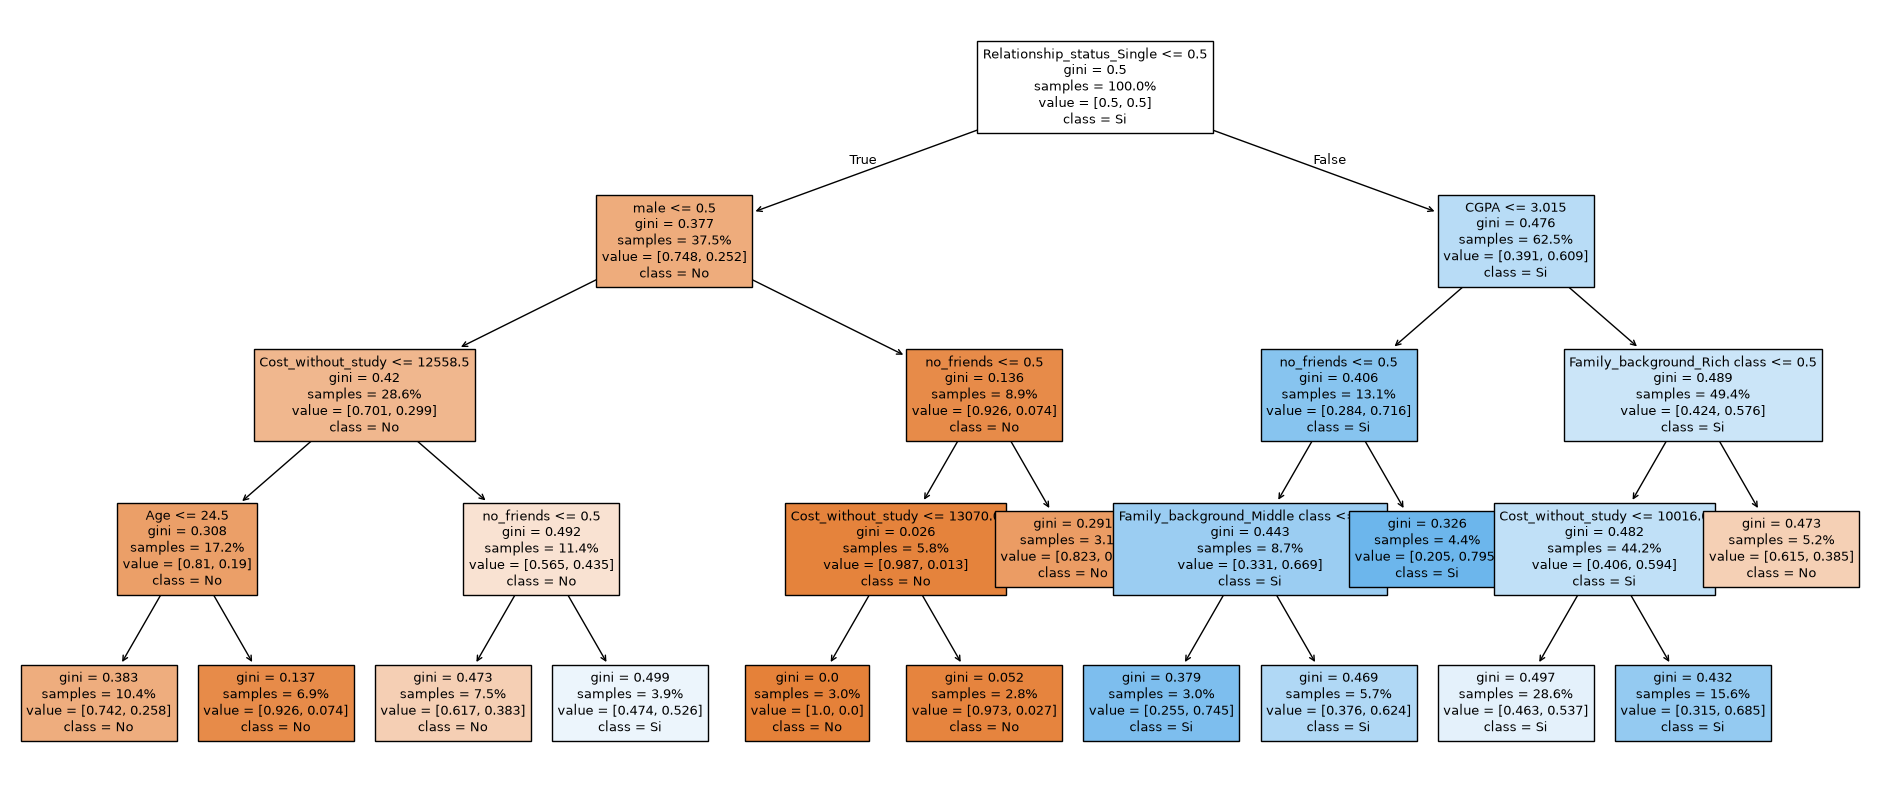

In [9]:
plt.figure(figsize=(24, 10))
skl_tree.plot_tree(tree, feature_names=list(X_train.columns), filled=True, class_names=["No", "Si"],
                   proportion=True, fontsize=9)
plt.show()

In [10]:
print(skl_tree.export_text(tree, feature_names=list(X_train.columns), show_weights=True))


|--- Relationship_status_Single <= 0.50
|   |--- male <= 0.50
|   |   |--- Cost_without_study <= 12558.50
|   |   |   |--- Age <= 24.50
|   |   |   |   |--- weights: [224.38, 78.03] class: 0
|   |   |   |--- Age >  24.50
|   |   |   |   |--- weights: [162.82, 13.01] class: 0
|   |   |--- Cost_without_study >  12558.50
|   |   |   |--- no_friends <= 0.50
|   |   |   |   |--- weights: [149.82, 92.90] class: 0
|   |   |   |--- no_friends >  0.50
|   |   |   |   |--- weights: [67.04, 74.32] class: 1
|   |--- male >  0.50
|   |   |--- no_friends <= 0.50
|   |   |   |--- Cost_without_study <= 13070.00
|   |   |   |   |--- weights: [73.88, 0.00] class: 0
|   |   |   |--- Cost_without_study >  13070.00
|   |   |   |   |--- weights: [67.73, 1.86] class: 0
|   |   |--- no_friends >  0.50
|   |   |   |--- weights: [69.09, 14.86] class: 0
|--- Relationship_status_Single >  0.50
|   |--- CGPA <= 3.01
|   |   |--- no_friends <= 0.50
|   |   |   |--- Family_background_Middle class <= 0.50
|   |   |  

**Importanza delle variabili**: quanto ogni variabile contribuisce a ridurre l'"impurità" (cioè a separare meglio depressi e non depressi) lungo tutto l'albero. Somma 1. È l'analogo, per l'albero, degli odds ratio della logistica, ma dice **quanto conta** una variabile, non in che direzione.

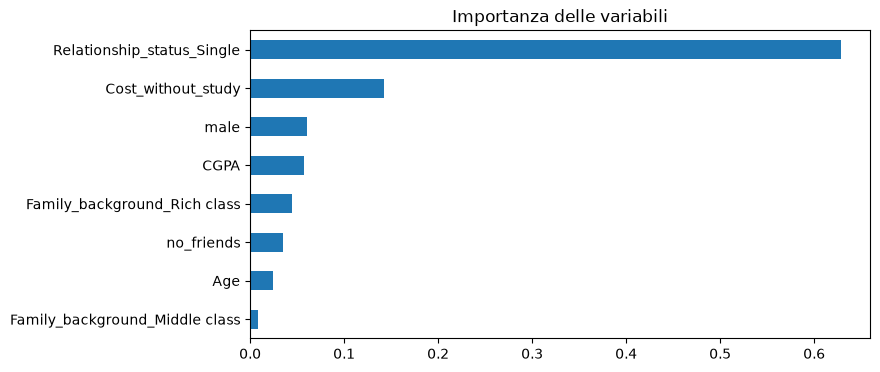

In [11]:
imp = pd.Series(tree.feature_importances_, index=X_train.columns).sort_values(ascending=False)
imp[imp > 0].head(10).sort_values().plot(kind="barh", figsize=(8, 4), title="Importanza delle variabili")
plt.show()

Occhio, favorisce variabili numeriche che hanno molte soglie da essere testate. Cost_without_study potrebbe essere sopravvalutato.

Misura cosa ha usato l'albero per imparare

Non dice la direzione, dice solo se conta

Scegliamo delle soglie che non siano 0.5.

Attento a non usare ne il test ma nemmeno il train. Usiamo quindi cross_val_predict, così ogni studente riceve il punteggio da un albero che non lo ha mai visto:

- diviamo in 5 fold

- per ogni fold, addestriamo su 4 e calcoliamo probabilità sul 5

- per tutti gli studenti del train, restituisce un punteggio fuori campione

In [12]:
p_cv = cross_val_predict(tree, X_train, y_train, cv = cv, method = 'predict_proba')[:,1]
#cosi teniamo la probabilità di depressione per ogni studente del train

righe = []

for t in np.arange(0.05, 0.96, 0.01):
    pred = (p_cv>=t).astype(int)
    #per ogni soglia, 1 se il punteggio lo supera, altrimenti 0
    righe.append([t,
                skl_metr.precision_score(y_train, pred, zero_division=0),
                skl_metr.recall_score(y_train, pred),
                skl_metr.f1_score(y_train, pred),
                skl_metr.matthews_corrcoef(y_train, pred)])

tab_soglie = pd.DataFrame(righe, columns=["soglia", "precision", "recall", "f-score", "phi-score"])

tab_soglie[(tab_soglie["soglia"] * 100).round().astype(int) % 5 == 0].reset_index(drop=True)



,soglia,precision,recall,f-score,phi-score
0,0.050,0.292,0.993,0.451,0.170
1,0.100,0.298,0.988,0.458,0.188
2,0.150,0.308,0.978,0.469,0.214
3,0.200,0.312,0.971,0.473,0.221
4,0.250,0.319,0.958,0.479,0.231
5,0.300,0.331,0.939,0.490,0.251
6,0.350,0.339,0.930,0.497,0.264
7,0.400,0.358,0.860,0.505,0.270
8,0.450,0.364,0.809,0.502,0.260
9,0.500,0.385,0.730,0.504,0.267


In [16]:
#scegliamo una soglia con una regola
#in questo caso decisiamo massimo f-score su cv, cosi stiamo neutri
SOGLIA = round(float(tab_soglie.loc[tab_soglie['f-score'].idxmax(), 'soglia']), 2)
#idxmax() prende riga con f-score più alto
#poi loc [riga, 'soglia'] prende la soglia

print("Soglia scelta (scenario ibrido):", SOGLIA)


prob_train = tree.predict_proba(X_train)[:, 1]
prob_test = tree.predict_proba(X_test)[:, 1]
#adesso inseriamo la soglia nella selezione
#occhio che devi mettere predict_proba (questa era la domanda di alessandro, importante)
pred_train = (tree.predict_proba(X_train)[:,1] >= SOGLIA).astype(int)
pred_test = (tree.predict_proba(X_test)[:,1] >= SOGLIA).astype(int)

# matrice di confusione: classe vera in riga, classe predetta in colonna
print(pd.crosstab(y_test, pred_test, rownames=["vero"], colnames=["predetto"]))

metriche = {
    "accuracy": skl_metr.accuracy_score,
    "precision": skl_metr.precision_score,
    "recall": skl_metr.recall_score,
    "f-score": skl_metr.f1_score,
    "phi-score": skl_metr.matthews_corrcoef,
}
df_metriche = pd.DataFrame({
    "train": {k: f(y_train, pred_train) for k, f in metriche.items()},
    "test": {k: f(y_test, pred_test) for k, f in metriche.items()},
})
df_metriche.loc["AUC"] = [skl_metr.roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1]),
                          skl_metr.roc_auc_score(y_test, tree.predict_proba(X_test)[:, 1])]
print(df_metriche)
print("Accuracy 'rispondo sempre No':", round(1 - y_test.mean(), 3))

Soglia scelta (scenario ibrido): 0.41
predetto    0    1
vero              
0         291  362
1          50  190
           train  test
accuracy   0.578 0.539
precision  0.375 0.344
recall     0.851 0.792
f-score    0.520 0.480
phi-score  0.299 0.217
AUC        0.725 0.675
Accuracy 'rispondo sempre No': 0.731


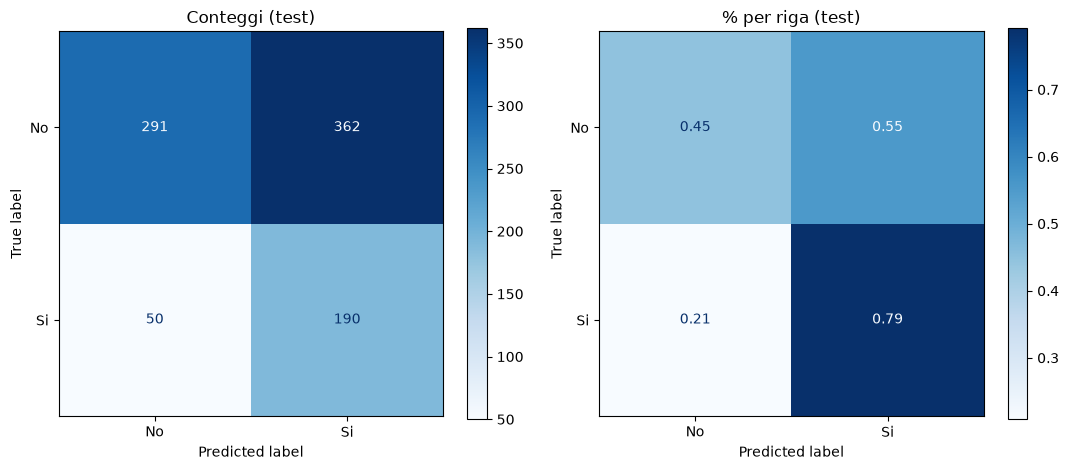

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
skl_metr.ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["No", "Si"],
                                                 cmap="Blues", values_format="d", ax=ax[0])
ax[0].set_title("Conteggi (test)")
skl_metr.ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["No", "Si"],
                                                 cmap="Blues", normalize="true", values_format=".2f", ax=ax[1])
ax[1].set_title("% per riga (test)")
plt.tight_layout()
plt.show()


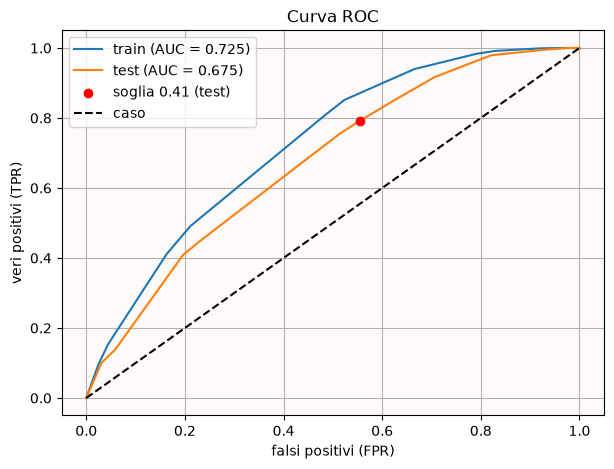

In [18]:
tn, fp, fn, tp = skl_metr.confusion_matrix(y_test, pred_test).ravel()

fig, ax = plt.subplots(figsize=(7, 5))
for nome, y, p in [("train", y_train, prob_train), ("test", y_test, prob_test)]:
    fpr, tpr, _ = skl_metr.roc_curve(y, p)
    ax.plot(fpr, tpr, label=f"{nome} (AUC = {skl_metr.roc_auc_score(y, p):.3f})")
ax.scatter(fp / (fp + tn), tp / (tp + fn), color="red", zorder=3, label=f"soglia {SOGLIA} (test)")
ax.plot([0, 1], [0, 1], "k--", label="caso")
ax.set_xlabel("falsi positivi (FPR)")
ax.set_ylabel("veri positivi (TPR)")
ax.set_title("Curva ROC")
ax.set_facecolor("snow")
ax.legend()
ax.grid()
plt.show()


### Confronto con la regressione logistica
Sul test (stessi studenti) la logistica aveva: accuracy 0,562, precision 0,346, recall 0,708, f-score 0,465, phi-score 0,193, AUC 0,664.

Confronta con la tabella sopra. Domande da farsi:
- l'**AUC** (che non dipende dalla soglia) è davvero diversa? Con 240 depressi nel test, differenze di 0,01-0,02 sono rumore;
- l'albero ha una **regola leggibile** (le domande) mentre la logistica ha coefficienti: quale delle due spiega meglio a un non tecnico perché uno studente è a rischio?
- lo scarto train-test dell'albero è accettabile?